<div dir="rtl">

# نوت‌بوک ۶: امکان‌پذیری بازه‌های زمانی

**فاز ۱، تسک ۱۰**

واحد گزارش پروژه «**یک محصول در یک بازه‌ی زمانی**» است (پیش‌فرض ۳ ماه). برای هر واحد، از روی نقدهای همان بازه به صاحب محصول می‌گوییم کدام جنبه‌ها را اول بهبود دهد. این نوت‌بوک می‌پرسد:

۱. چند «محصول در یک بازه» نقد **کافی** دارند؟ کافی یعنی چند نقد؟
۲. چون گزارش درباره‌ی **شکایت‌ها**ست، چند واحد **نقد منفی** کافی هم دارند؟
۳. اگر طول بازه را ۱ یا ۶ ماه بگیریم، این اعداد چطور عوض می‌شوند؟
۴. بازه‌ی زمانی تحلیل از کجا تا کجا باشد؟

در پایان، **آستانه‌ی حداقل نقد** و **بازه‌ی زمانی تحلیل** را انتخاب و قبل از مدل‌سازی ثبت می‌کنیم.

</div>

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load(open(ROOT / "configs" / "config.yaml", encoding="utf-8"))
PROC = ROOT / cfg["data"]["processed_dir"]
FIG = ROOT / "figures"
WINDOW_MONTHS = cfg["window"]["months"]

pd.set_option("display.width", 200)
BAR, NEG = "#3B6EA8", "#B5523B"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9,
})

reviews = (pd.read_parquet(PROC / "reviews_rc.parquet",
                           columns=["parent_asin", "user_id", "rating", "timestamp", "text"])
             .drop_duplicates().reset_index(drop=True))
reviews["date"] = pd.to_datetime(reviews["timestamp"], unit="ms")
reviews["negative"] = reviews["rating"] <= 2
print(f"reviews: {len(reviews):,}   window length from config: {WINDOW_MONTHS} months")

reviews: 851,749   window length from config: 3 months


<div dir="rtl">

## ۱. ساختن بازه‌ها

بازه‌ها **تقویمی** و هم‌طول‌اند: برای ۳ ماه یعنی ژانویه تا مارس، آوریل تا ژوئن و ... . بازه‌ی تقویمی دو مزیت دارد: برای همه‌ی محصولات یکسان است، و صاحب محصول هم معمولاً فصلی برنامه‌ریزی می‌کند.

تابع زیر طول بازه را به‌عنوان ورودی می‌گیرد تا بتوانیم ۱ و ۶ ماه را هم امتحان کنیم.

</div>

In [2]:
def add_window(df, months):
    month_index = df["date"].dt.year * 12 + df["date"].dt.month - 1
    start_index = (month_index // months) * months
    year, month = start_index // 12, start_index % 12 + 1
    return pd.to_datetime(pd.DataFrame({"year": year, "month": month, "day": 1}))

def window_table(df, months):
    w = df.assign(window=add_window(df, months))
    return (w.groupby(["parent_asin", "window"])
             .agg(reviews=("rating", "size"), negatives=("negative", "sum"),
                  mean_rating=("rating", "mean"))
             .reset_index())

units = window_table(reviews, WINDOW_MONTHS)
print(f"product-windows with at least one review: {len(units):,}")
units["reviews"].describe(percentiles=[.5, .75, .9, .95, .99]).round(1)

product-windows with at least one review: 254,573


count    254573.0
mean          3.3
std          13.7
min           1.0
50%           1.0
75%           2.0
90%           5.0
95%           9.0
99%          37.0
max        1311.0
Name: reviews, dtype: float64

<div dir="rtl">

## ۲. با چه آستانه‌ای چند واحد داریم؟

برای هر آستانه‌ی «حداقل نقد در بازه» می‌شماریم:

- چند واحد (محصول در یک بازه) واجد شرایط‌اند
- این واحدها از چند **محصول مختلف** می‌آیند
- چند درصد **کل نقدها** در این واحدها هستند

</div>

In [3]:
total_reviews = len(reviews)
rows = []
for k in [5, 10, 15, 20, 30, 50, 100]:
    ok = units[units["reviews"] >= k]
    rows.append({"min_reviews": k, "units": len(ok), "products": ok["parent_asin"].nunique(),
                 "reviews_covered_%": round(100 * ok["reviews"].sum() / total_reviews, 1),
                 "median_reviews_per_unit": ok["reviews"].median()})
threshold_table = pd.DataFrame(rows).set_index("min_reviews")
threshold_table

,units,products,reviews_covered_%,median_reviews_per_unit
min_reviews,,,,
5,29261,8090,61.2,8.0
10,12523,3428,48.7,17.0
15,7700,2126,42.2,26.0
20,5525,1471,37.9,35.0
30,3385,886,31.9,51.0
50,1763,476,24.7,85.0
100,684,187,16.0,157.0


<div dir="rtl">

## ۳. نقد منفی کافی

گزارش ما از **شکایت‌ها** ساخته می‌شود. واحدی که ۴۰ نقد دارد ولی همه ۵ ستاره‌اند، چیزی برای اولویت‌بندی ندارد. پس علاوه بر کل نقد، تعداد نقدهای **منفی** (۱ و ۲ ستاره) را هم می‌شماریم.

</div>

In [4]:
grid = pd.DataFrame(
    {f">= {m} negative": [(units[(units["reviews"] >= k) & (units["negatives"] >= m)]).shape[0]
                          for k in [10, 20, 30, 50]]
     for m in [0, 3, 5, 10]},
    index=pd.Index([10, 20, 30, 50], name="min_reviews"))
grid

,>= 0 negative,>= 3 negative,>= 5 negative,>= 10 negative
min_reviews,,,,
10,12523,7519,5022,2049
20,5525,4434,3573,1930
30,3385,2990,2607,1660
50,1763,1661,1548,1186


<div dir="rtl">

## ۴. حساسیت به طول بازه

همان شمارش را با بازه‌های ۱، ۳ و ۶ ماهه تکرار می‌کنیم. بازه‌ی کوتاه‌تر به‌روزتر است ولی نقد کمتری در هر واحد دارد؛ بازه‌ی بلندتر نقد بیشتری دارد ولی کندتر به تغییرات محصول واکنش نشان می‌دهد.

</div>

In [5]:
rows = []
for months in [1, 3, 6]:
    u = units if months == WINDOW_MONTHS else window_table(reviews, months)
    for k in [10, 20, 30]:
        ok = u[(u["reviews"] >= k)]
        rows.append({"window_months": months, "min_reviews": k, "units": len(ok),
                     "products": ok["parent_asin"].nunique(),
                     "units_with_>=5_negatives": int((ok["negatives"] >= 5).sum())})
sensitivity = pd.DataFrame(rows).pivot(index="min_reviews", columns="window_months")
sensitivity

units               products             units_with_>=5_negatives            
window_months      1      3      6        1     3     6                        1     3     6
min_reviews                                                                                 
10             11114  12523  13178     1782  3428  4926                     3710  5022  5301
20              4463   5525   5884      719  1471  2188                     2460  3573  3915
30              2563   3385   3665      433   886  1298                     1678  2607  2911

<div dir="rtl">

## ۵. واحدهای واجد شرایط در طول زمان

با آستانه‌ی پیشنهادی ۲۰ نقد، تعداد واحدهای واجد شرایط را برای هر سال می‌شماریم. این نشان می‌دهد تحلیل از چه سالی معنادار می‌شود و آیا سال آخر (۲۰۲۳) قابل استفاده است.

</div>

In [6]:
K = 20
eligible = units[units["reviews"] >= K].copy()
eligible["year"] = eligible["window"].dt.year
per_window = units.assign(eligible=units["reviews"] >= K).groupby("window")["eligible"].sum()
per_year = eligible.groupby("year").agg(units=("reviews", "size"),
                                         products=("parent_asin", "nunique"),
                                         mean_negative_share=("negatives", "sum"))
per_year["mean_negative_share"] = (100 * per_year["mean_negative_share"]
                                   / eligible.groupby("year")["reviews"].sum()).round(1)
per_year.T

year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
units,1.0,6.0,30.0,45.0,89.0,209.0,407.0,459.0,435.0,418.0,530.0,825.0,912.0,814.0,345.0
products,1.0,4.0,11.0,21.0,44.0,106.0,210.0,232.0,264.0,225.0,267.0,413.0,434.0,464.0,276.0
mean_negative_share,2.6,13.1,19.2,20.3,15.2,16.5,18.1,18.7,18.1,14.7,14.2,13.5,17.3,20.9,19.1


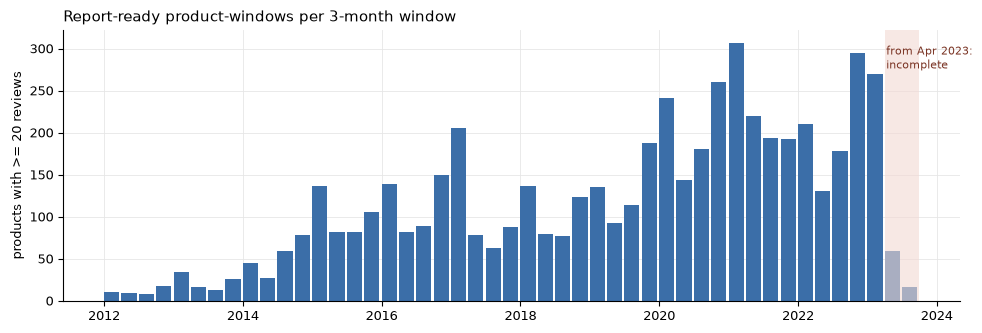

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.4))
s = per_window[per_window.index >= "2012-01-01"]
ax.bar(s.index, s.values, width=80, color=BAR, align="edge")
last = reviews["date"].max()
ax.axvspan(pd.Timestamp("2023-04-01"), s.index.max() + pd.Timedelta(days=92),
           color="#f3d9d3", alpha=0.6, lw=0)
ax.text(pd.Timestamp("2023-04-10"), s.max() * 0.9, "from Apr 2023:\nincomplete", fontsize=8, color="#7a3424")
ax.set_ylabel(f"products with >= {K} reviews")
ax.set_title(f"Report-ready product-windows per {WINDOW_MONTHS}-month window", loc="left")
plt.tight_layout()
plt.savefig(FIG / "fig14_eligible_windows.png", dpi=200, bbox_inches="tight")
plt.show()

<div dir="rtl">

## ۶. بازه‌ی تقویمی ناقص آخر

آخرین نقد داده در شهریور ۲۰۲۳ است. بازه‌ای که هنوز تمام نشده بود، به‌صورت ساختاری نقد کمتری دارد. سهم نقدهای هر بازه‌ی ۲۰۲۳ را با همان بازه در ۲۰۲۲ مقایسه می‌کنیم:

</div>

In [8]:
q = reviews.assign(window=add_window(reviews, WINDOW_MONTHS)).groupby("window").size()
compare = pd.DataFrame({"2022": q[q.index.year == 2022].values[:4],
                        "2023": list(q[q.index.year == 2023].values) + [0] * (4 - (q.index.year == 2023).sum())},
                       index=[f"window {i + 1}" for i in range(4)])
compare["2023 as % of 2022"] = (100 * compare["2023"] / compare["2022"]).round(0)
compare

,2022,2023,2023 as % of 2022
window 1,30547,37199,122.0
window 2,23707,14799,62.0
window 3,28251,4379,16.0
window 4,37133,0,0.0


<div dir="rtl">

## ۷. تصمیم‌ها

تأییدشده در ۵ آبان ۱۴۰۵ (تسک ۱۰) و ثبت‌شده در کارت پروژه (بند ۱) و `configs/config.yaml`:

| تصمیم | انتخاب | دلیل |
|---|---|---|
| طول بازه | ۳ ماه تقویمی | تعادل بین به‌روز بودن و تعداد نقد؛ ۱ و ۶ ماه در فاز ۴ به‌عنوان تحلیل حساسیت |
| حداقل نقد در بازه | ۲۰ نقد | در کل داده ۵٬۵۲۵ واحد از ۱٬۴۷۱ محصول (۳۷٫۹٪ نقدها)؛ ۳٬۵۷۳ تای آن‌ها دست‌کم ۵ نقد منفی دارند. آستانه فقط روی **تعداد** نقد است، نه امتیاز |
| شروع بازه‌ی تحلیل | ژانویه‌ی ۲۰۱۵ | پیش از آن کمتر از ۲۰۰ واحد واجد شرایط در سال |
| پایان بازه‌ی تحلیل | مارس ۲۰۲۳ | سه‌ماهه‌ی دوم ۲۰۲۳ فقط ۶۲٪ و سه‌ماهه‌ی سوم ۱۶٪ نقدهای همان بازه در ۲۰۲۲ را دارند |

## ۸. جمع‌بندی

- **چه دیدیم:** نقدها بین محصولات بسیار نابرابر پخش شده‌اند. بیشتر «محصول در یک بازه»‌ها فقط چند نقد دارند و یک اقلیت کوچک بخش بزرگی از نقدها را دارد. با آستانه‌ی ۲۰ نقد، حدود ۳۸٪ نقدها در واحدهای واجد گزارش قرار می‌گیرند.
- **چرا مهم است:** گزارش اولویت‌بندی از روی چند نقد معدود قابل اعتماد نیست. از طرف دیگر، آستانه‌ی خیلی بالا بیشتر محصولات را حذف می‌کند و گزارش فقط به محصولات پرفروش محدود می‌شود.
- **چه می‌کنیم:** آستانه‌ی ۲۰ نقد، بازه‌ی ۳ ماهه و دوره‌ی ژانویه‌ی ۲۰۱۵ تا مارس ۲۰۲۳. محصولاتی که به آستانه نمی‌رسند، در آموزش مدل امتیاز استفاده می‌شوند ولی گزارش جداگانه نمی‌گیرند.
- **محدودیت:** واحدهای واجد گزارش به سمت محصولات محبوب‌تر سوگیری دارند. نتایج گزارش برای این محصولات معتبر است، نه برای محصولات کم‌نقد.

</div>

<div dir="rtl">

## ۹. جفت بازه‌های متوالی (تسک ۱۳)

لایه‌ی ۳ ارزیابی (کارت پروژه، بند ۹) به **جفت بازه‌های متوالی** نیاز دارد: همان محصول در دو سه‌ماهه‌ی پشت سر هم (t و t+1) که **هر دو** دست‌کم ۲۰ نقد داشته باشند. در بازه‌ی t پیشنهاد می‌دهیم و در t+1 می‌بینیم چه شد. سؤال اولیه‌ی «هشدار زودهنگام» (بند ۶) هم همین جفت‌ها را لازم دارد.

این بخش فقط روی **دوره‌ی تحلیل** (ژانویه‌ی ۲۰۱۵ تا مارس ۲۰۲۳) است. هر جفت به بخشی تعلق دارد که بازه‌ی t+1 در آن است.

</div>

In [9]:
import sys
sys.path.insert(0, str(ROOT / "src"))
from splits import assign_split

period = reviews.assign(split=assign_split(reviews["date"], cfg))
period = period[period["split"] != "out_of_range"]
print(f"reviews in the analysis period: {len(period):,}")

pu = window_table(period, WINDOW_MONTHS)
pu = pu[pu["reviews"] >= K].sort_values(["parent_asin", "window"]).reset_index(drop=True)
pu["split"] = assign_split(pu["window"], cfg)
print(f"report-ready units in the analysis period: {len(pu):,} from {pu['parent_asin'].nunique():,} products "
      f"({100 * pu['reviews'].sum() / len(period):.1f}% of reviews)")
print(pu["split"].value_counts().reindex(["train", "validation", "test"]).to_string())

reviews in the analysis period: 777,860


report-ready units in the analysis period: 5,070 from 1,426 products (38.0% of reviews)
split
train         3074
validation     912
test          1084


In [10]:
nxt = pu.groupby("parent_asin")[["window", "reviews", "negatives", "split"]].shift(-1)
consecutive = nxt["window"] == pu["window"] + pd.DateOffset(months=WINDOW_MONTHS)
pairs = pd.DataFrame({
    "parent_asin": pu["parent_asin"],
    "window_t": pu["window"],
    "neg_share_t": pu["negatives"] / pu["reviews"],
    "neg_share_t1": nxt["negatives"] / nxt["reviews"],
    "split": nxt["split"],          # a pair belongs to the split of its t+1 window
})[consecutive]

pair_table = (pairs.groupby("split")
                   .agg(pairs=("parent_asin", "size"), products=("parent_asin", "nunique"))
                   .reindex(["train", "validation", "test"]))
pair_table.loc["total"] = [len(pairs), pairs["parent_asin"].nunique()]
pair_table

,pairs,products
split,,
train,1839,526
validation,662,292
test,641,272
total,3142,786


<div dir="rtl">

برای سؤال «هشدار زودهنگام» باید بدانیم آیا هر دو حالت «بدتر شد» و «بدتر نشد» نمونه‌ی کافی دارند. این را **فقط روی جفت‌های آموزش** نگاه می‌کنیم تا از امتیازهای دوره‌ی آزمون استفاده نشود:

</div>

In [11]:
train_pairs = pairs[pairs["split"] == "train"]
rose = (train_pairs["neg_share_t1"] - train_pairs["neg_share_t"]) >= 0.05
print(f"train pairs where the negative share rose by >= 5 percentage points: {rose.mean():.1%} "
      f"({rose.sum():,} of {len(train_pairs):,})")

train pairs where the negative share rose by >= 5 percentage points: 30.1% (553 of 1,839)


<div dir="rtl">

**نتیجه:** حدود ۳٬۱۰۰ جفت بازه‌ی متوالی از حدود ۸۰۰ محصول داریم و چند صد جفت از آن‌ها در دوره‌ی آزمون‌اند. پس لایه‌ی ۳ ارزیابی داده‌ی کافی دارد. در حدود ۳۰٪ جفت‌های آموزش، سهم نقد منفی دست‌کم ۵ واحد درصد بالا رفته است، پس سؤال «هشدار زودهنگام» هم از نظر داده شدنی بود. دلیل کنار گذاشتنش در بند ۶ کارت پروژه آمده است.

</div>